In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)

print("EDA environment is ready!")


EDA environment is ready!


In [5]:

# The notebook lives inside notebooks/
# so its parent directory is the project root.
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"

train_df = pd.read_csv(DATA_DIR / "train-test.csv")
validation_df = pd.read_csv(DATA_DIR / "validation.csv")

print("Training dataset loaded:", train_df.shape)
print("Validation dataset loaded:", validation_df.shape)


Training dataset loaded: (48000, 14)
Validation dataset loaded: (12000, 13)


In [6]:

train_df.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [7]:

validation_df.head()


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [9]:

train_df["date"] = pd.to_datetime(
    train_df["date"], errors="coerce"
)

validation_df["date"] = pd.to_datetime(
    validation_df["date"], errors="coerce"
)

print(train_df["date"].dtype)


datetime64[ns]


# Find the missing values

In [10]:

missing_count = train_df.isnull().sum()

missing_percentage = (
    train_df.isnull().mean() * 100
)

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percentage": missing_percentage
})

display(
    missing_summary[
        missing_summary["missing_count"] > 0
    ].round(2)
)


,missing_count,missing_percentage
weight,300,0.62
market_index,374,0.78


In [11]:

quality_checks = {
    "duplicate_load_ids": train_df["load_id"].duplicated().sum(),
    "duplicate_rows": train_df.duplicated().sum(),
    "negative_weights": (train_df["weight"] < 0).sum(),
    "zero_or_negative_distance": (train_df["distance"] <= 0).sum(),
    "zero_or_negative_rates": (train_df["posted_rate"] <= 0).sum(),
    "invalid_dates": train_df["date"].isna().sum()
}

pd.Series(quality_checks)


duplicate_load_ids             0
duplicate_rows                 0
negative_weights             292
zero_or_negative_distance      0
zero_or_negative_rates         0
invalid_dates                  0
dtype: int64

In [12]:

train_df["posted_rate"].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
)


count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
1%         327.168800
25%       1251.555000
50%       2030.760000
75%       3330.750000
99%       5972.834000
max      25533.000000
Name: posted_rate, dtype: float64

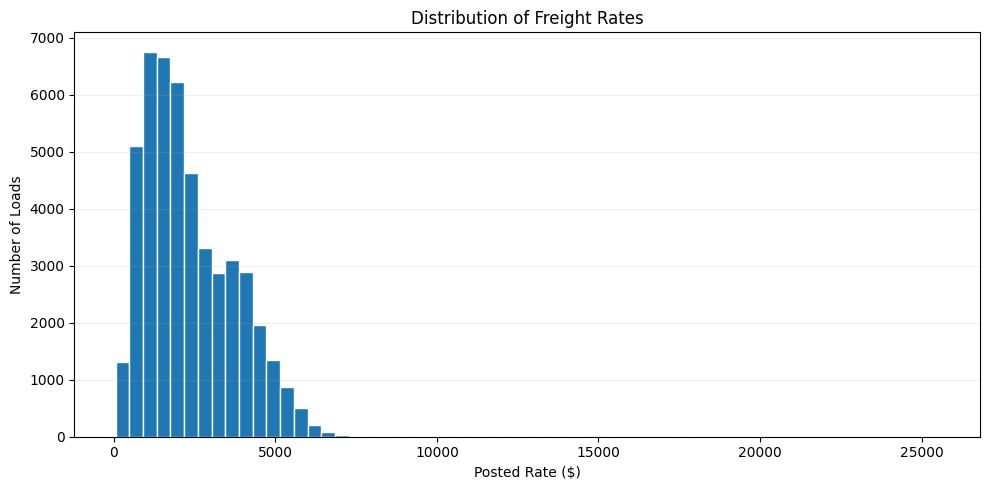

In [13]:

plt.figure(figsize=(10, 5))

plt.hist(
    train_df["posted_rate"],
    bins=60,
    edgecolor="white"
)

plt.title("Distribution of Freight Rates")
plt.xlabel("Posted Rate ($)")
plt.ylabel("Number of Loads")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


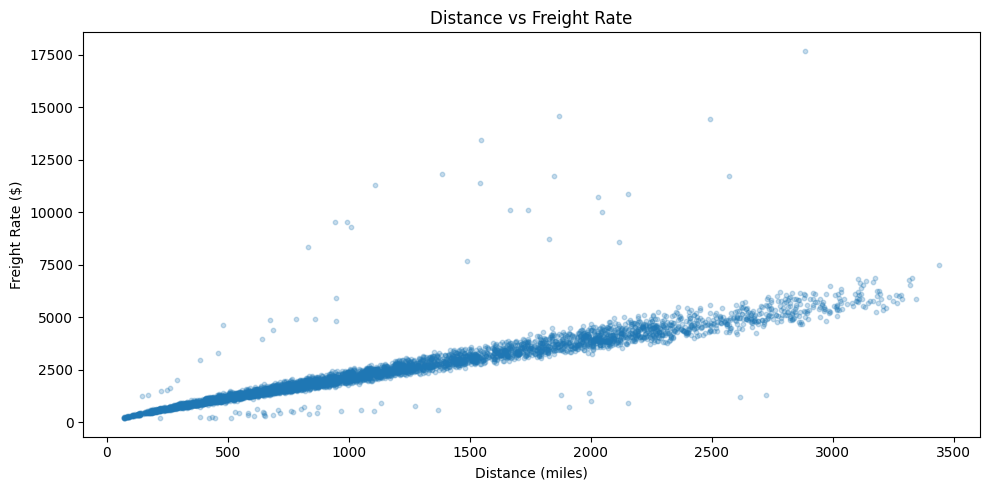

             distance  posted_rate
distance     1.000000     0.908519
posted_rate  0.908519     1.000000


In [14]:

sample = train_df.sample(
    n=5000,
    random_state=42
)

plt.figure(figsize=(10, 5))

plt.scatter(
    sample["distance"],
    sample["posted_rate"],
    alpha=0.25,
    s=10
)

plt.xlabel("Distance (miles)")
plt.ylabel("Freight Rate ($)")
plt.title("Distance vs Freight Rate")

plt.tight_layout()
plt.show()

correlation = train_df[
    ["distance", "posted_rate"]
].corr()

print(correlation)


In [15]:

train_df["rate_per_mile"] = (
    train_df["posted_rate"] / train_df["distance"]
)

equipment_summary = (
    train_df.groupby("equipment")
    .agg(
        loads=("load_id", "count"),
        median_rate=("posted_rate", "median"),
        median_rate_per_mile=("rate_per_mile", "median")
    )
    .round(2)
)

display(equipment_summary)


,loads,median_rate,median_rate_per_mile
equipment,,,
Dry Van,27202,1953.04,2.05
Flatbed,8753,2076.81,2.22
Reefer,12045,2196.67,2.31


,loads,median_rate,median_rpm
month,,,
2025-01,4918,1915.20,2.03
2025-02,4337,1994.25,2.06
2025-03,5036,2022.92,2.14
2025-04,4819,2044.24,2.15
2025-05,4913,2065.51,2.19
2025-06,4783,2120.22,2.25
2025-07,4912,2059.14,2.19
2025-08,4759,2015.73,2.12
2025-09,4670,2057.13,2.16


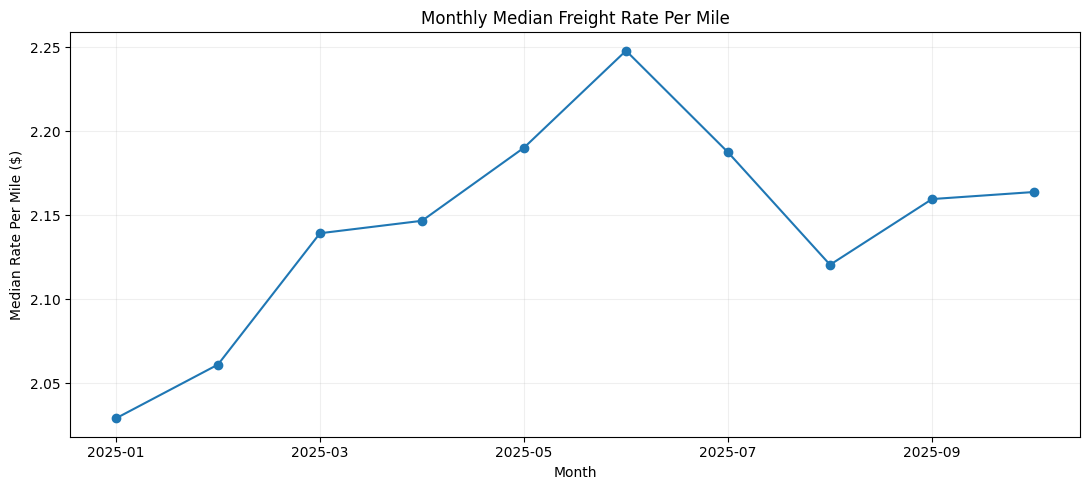

In [16]:

train_df["month"] = (
    train_df["date"].dt.to_period("M").astype(str)
)

monthly_summary = (
    train_df.groupby("month")
    .agg(
        loads=("load_id", "count"),
        median_rate=("posted_rate", "median"),
        median_rpm=("rate_per_mile", "median")
    )
)

display(monthly_summary.round(2))

monthly_summary["median_rpm"].plot(
    figsize=(11, 5),
    marker="o",
    title="Monthly Median Freight Rate Per Mile"
)

plt.xlabel("Month")
plt.ylabel("Median Rate Per Mile ($)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()



In [17]:

print("Training:", train_df["date"].min(), "to",
      train_df["date"].max())

print("Validation:", validation_df["date"].min(), "to",
      validation_df["date"].max())


Training: 2025-01-01 00:00:00 to 2025-10-31 00:00:00
Validation: 2025-11-01 00:00:00 to 2025-12-31 00:00:00


In [18]:

train_cities = (
    set(train_df["pickup"]) |
    set(train_df["delivery"])
)

validation_cities = (
    set(validation_df["pickup"]) |
    set(validation_df["delivery"])
)

unseen_cities = sorted(
    validation_cities - train_cities
)

print("Training cities:", len(train_cities))
print("Validation cities:", len(validation_cities))
print("Unseen cities:", len(unseen_cities))
print("Cities:", unseen_cities)


Training cities: 64
Validation cities: 72
Unseen cities: 8
Cities: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']


In [20]:

december_df = pd.read_csv(
    DATA_DIR / "december-chart-inputs.csv"
)

print("Training columns:")
print(train_df.columns.tolist())

print("\nFinal validation columns:")
print(validation_df.columns.tolist())

print("\nDecember chart columns:")
print(december_df.columns.tolist())


Training columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate', 'rate_per_mile', 'month']

Final validation columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']

December chart columns:
['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
